In [1]:
import numpy as np
import pandas as pd
from numpy import loadtxt
from numpy import exp


from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import accuracy_score,mean_absolute_error,mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
import sklearn.datasets
from keras.wrappers.scikit_learn import KerasRegressor,KerasClassifier
from torch.autograd import Variable

import torch
from torch import nn
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torch.utils.data import Dataset, TensorDataset
import torch.nn.functional as F
#from pytorchtools import EarlyStopping


%matplotlib inline

pd.set_option('max_rows',999)
#Detect device
device = 'cuda' if torch.cuda.is_available() else 'cpu'

#### define fucntions

In [2]:
from torch.autograd import Variable

In [3]:
def train_test_validation_tscv(df_data=pd.DataFrame(),
                               df_target=pd.DataFrame()):
    X=df_data
    y=df_target
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3)

    X_train_tensor = Variable(torch.FloatTensor(X_train))
    y_train_tensor = Variable(torch.FloatTensor(y_train))

    train_data = TensorDataset(X_train_tensor, y_train_tensor)
    train_loader = DataLoader(dataset=train_data, batch_size=64)        
        
    return train_loader, X_test,  y_test

In [47]:
def train_test_validation_tscv(df_data=pd.DataFrame(),
                               df_target=pd.DataFrame(),):
    X=df_data
    y=df_target
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3)
    X_train, X_valid, y_train, y_valid = train_test_split(X_train,y_train,test_size=0.2)
        
    x_train_tensor = torch.from_numpy(X_train).float().to(device)
    y_train_tensor = torch.from_numpy(y_train).float().to(device)

    x_valid_tensor = torch.from_numpy(X_valid).float().to(device)
    y_valid_tensor = torch.from_numpy(y_valid).float().to(device)


    train_data = TensorDataset(x_train_tensor, y_train_tensor)
    train_loader = DataLoader(dataset=train_data, batch_size=64)
 
 
    valid_data = TensorDataset(x_valid_tensor, y_valid_tensor)
    valid_loader = DataLoader(dataset=valid_data, batch_size=64)
        
        
    return train_loader,valid_loader, X_train, y_train, X_valid, y_valid, X_test,  y_test


class MLP(nn.Module):
    def __init__(self,dim_input=13):
        super().__init__()
        neurons = 25
        # define an MLP layers
        self.fc1 = nn.Linear(in_features=dim_input, out_features=neurons)
        self.fc2 = nn.Linear(in_features=neurons, out_features=neurons)
        self.fc3 = nn.Linear(in_features=neurons, out_features=neurons)
        self.fc4 = nn.Linear(in_features=neurons, out_features=neurons)
        
        self.output = nn.Linear(in_features=neurons, out_features=1)

    def forward(self, x):
        
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = F.relu(self.fc4(x))
        
        x = self.output(x)
        return x
    
def train_model(df_data,df_target,model):

    train_loader,valid_loader ,X_train, y_train, X_valid, y_valid, X_test,  y_test = train_test_validation_tscv(df_data,df_target)
    criterion = torch.nn.MSELoss(reduction='sum')
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.01)
    epochs = 5000

    # to track the training loss as the model trains
    train_losses = []
    # to track the validation loss as the model trains
    valid_losses = []
    # to track the average training loss per epoch as the model trains
    avg_train_losses = []
    # to track the average validation loss per epoch as the model trains
    avg_valid_losses = [] 
    
    
    patience = 50
    trigger_times = 0
    
    for i in range(epochs):
        model.train()
        for x_batch, y_batch in train_loader:

            x_batch,y_batch = x_batch.to(device),y_batch.to(device) 
            
            # clear the gradients of all optimized variables
            optimizer.zero_grad()
            # Makes predictions
            yhat = model.forward(x_batch)
            # Computes loss
            loss = criterion(torch.unsqueeze(y_batch,dim=1), yhat)
            #print('unsqueeze:', torch.unsqueeze(y_batch,dim=1))
            #print('normal: ',y_batch)
            #loss = criterion(y_batch, yhat)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())
        
        train_loss = np.average(train_losses)
        avg_train_losses.append(train_loss)
        
        model.eval()     
        for x_batch, y_batch in valid_loader:
            yhat = model.forward(x_batch)
            loss = criterion(torch.unsqueeze(y_batch,dim=1), yhat)
            valid_losses.append(loss.item())

        valid_loss = np.average(valid_losses)
        avg_valid_losses.append(valid_loss)
        
        # clear lists to track next epoch
        train_losses = []
        
        # early_stopping needs the validation loss to check if it has decresed, 
        # and if it has, it will make a checkpoint of the current model
        print('Epoch: %.2f Loss train: %.2f - Loss valid: %.2f' % (i,avg_train_losses[-1],avg_valid_losses[-1]) )   
        if len(avg_valid_losses)>1:
            if (avg_valid_losses[-1]+0.01)  >= (avg_valid_losses[-2]):
                trigger_times += 1
                print('trigger times:', trigger_times)

                #ExponentialLR
                #scheduler.step()
                if trigger_times >= patience:
                    print('Early stopping!\nStart to test process.')
                    break

            else:
                print('trigger times: 0')
                trigger_times = 0
            
         
            
    return model,avg_train_losses[1:], avg_valid_losses[1:],X_train, y_train, X_test, y_test

def evaluate(model, X_test,y_test):
    preds = []
    X_test_tensor = torch.from_numpy(X_test).float().to(device)
    model.eval()   
    with torch.no_grad():
        
        for val in X_test_tensor:
            y_hat = model.forward(val.unsqueeze(0))
            #print(y_hat)
            preds.append(y_hat.item())
    mae=mean_absolute_error(y_test,preds)
    print('MAE: %.2f' % mae)        
    return preds,mae

#### train

In [48]:
data=sklearn.datasets.load_boston()['data']
target = sklearn.datasets.load_boston()['target']
model_MLP,losses_calendar, val_losses_calendar,X_train, y_test, X_test, y_test = train_model(data,
                                                                                                    target, 
                                                                                                    MLP(13).to(device))
pred_model_MLP,mae=evaluate(model_MLP,
         X_test,
         y_test)

Epoch: 0.00 Loss train: 35636.42 - Loss valid: 18188.15
Epoch: 1.00 Loss train: 28804.80 - Loss valid: 16437.68
trigger times: 0
Epoch: 2.00 Loss train: 23153.87 - Loss valid: 14766.53
trigger times: 0
Epoch: 3.00 Loss train: 17692.23 - Loss valid: 13158.56
trigger times: 0
Epoch: 4.00 Loss train: 12638.74 - Loss valid: 11705.39
trigger times: 0
Epoch: 5.00 Loss train: 8979.01 - Loss valid: 10556.98
trigger times: 0
Epoch: 6.00 Loss train: 7595.30 - Loss valid: 9763.18
trigger times: 0
Epoch: 7.00 Loss train: 7776.71 - Loss valid: 9182.58
trigger times: 0
Epoch: 8.00 Loss train: 7547.58 - Loss valid: 8672.35
trigger times: 0
Epoch: 9.00 Loss train: 6866.00 - Loss valid: 8219.70
trigger times: 0
Epoch: 10.00 Loss train: 6527.22 - Loss valid: 7830.98
trigger times: 0
Epoch: 11.00 Loss train: 6400.55 - Loss valid: 7492.97
trigger times: 0
Epoch: 12.00 Loss train: 6190.96 - Loss valid: 7190.34
trigger times: 0
Epoch: 13.00 Loss train: 5883.07 - Loss valid: 6915.23
trigger times: 0
Epoch: 1

Epoch: 123.00 Loss train: 1357.92 - Loss valid: 1921.15
trigger times: 0
Epoch: 124.00 Loss train: 1340.96 - Loss valid: 1912.44
trigger times: 0
Epoch: 125.00 Loss train: 1321.48 - Loss valid: 1903.88
trigger times: 0
Epoch: 126.00 Loss train: 1312.86 - Loss valid: 1895.47
trigger times: 0
Epoch: 127.00 Loss train: 1298.66 - Loss valid: 1887.20
trigger times: 0
Epoch: 128.00 Loss train: 1278.32 - Loss valid: 1879.04
trigger times: 0
Epoch: 129.00 Loss train: 1269.90 - Loss valid: 1871.02
trigger times: 0
Epoch: 130.00 Loss train: 1261.54 - Loss valid: 1863.14
trigger times: 0
Epoch: 131.00 Loss train: 1244.27 - Loss valid: 1855.40
trigger times: 0
Epoch: 132.00 Loss train: 1232.66 - Loss valid: 1847.79
trigger times: 0
Epoch: 133.00 Loss train: 1226.55 - Loss valid: 1840.28
trigger times: 0
Epoch: 134.00 Loss train: 1216.93 - Loss valid: 1832.88
trigger times: 0
Epoch: 135.00 Loss train: 1200.95 - Loss valid: 1825.59
trigger times: 0
Epoch: 136.00 Loss train: 1194.99 - Loss valid: 181

Epoch: 236.00 Loss train: 947.81 - Loss valid: 1373.70
trigger times: 0
Epoch: 237.00 Loss train: 948.24 - Loss valid: 1370.93
trigger times: 0
Epoch: 238.00 Loss train: 943.74 - Loss valid: 1368.21
trigger times: 0
Epoch: 239.00 Loss train: 943.17 - Loss valid: 1365.52
trigger times: 0
Epoch: 240.00 Loss train: 944.67 - Loss valid: 1362.84
trigger times: 0
Epoch: 241.00 Loss train: 944.35 - Loss valid: 1360.19
trigger times: 0
Epoch: 242.00 Loss train: 942.28 - Loss valid: 1357.55
trigger times: 0
Epoch: 243.00 Loss train: 939.11 - Loss valid: 1354.93
trigger times: 0
Epoch: 244.00 Loss train: 940.03 - Loss valid: 1352.32
trigger times: 0
Epoch: 245.00 Loss train: 940.40 - Loss valid: 1349.72
trigger times: 0
Epoch: 246.00 Loss train: 937.58 - Loss valid: 1347.14
trigger times: 0
Epoch: 247.00 Loss train: 941.89 - Loss valid: 1344.58
trigger times: 0
Epoch: 248.00 Loss train: 935.02 - Loss valid: 1342.05
trigger times: 0
Epoch: 249.00 Loss train: 935.52 - Loss valid: 1339.55
trigger t

Epoch: 351.00 Loss train: 868.47 - Loss valid: 1149.51
trigger times: 0
Epoch: 352.00 Loss train: 868.80 - Loss valid: 1148.11
trigger times: 0
Epoch: 353.00 Loss train: 864.71 - Loss valid: 1146.73
trigger times: 0
Epoch: 354.00 Loss train: 861.15 - Loss valid: 1145.36
trigger times: 0
Epoch: 355.00 Loss train: 866.04 - Loss valid: 1144.00
trigger times: 0
Epoch: 356.00 Loss train: 866.15 - Loss valid: 1142.64
trigger times: 0
Epoch: 357.00 Loss train: 861.60 - Loss valid: 1141.29
trigger times: 0
Epoch: 358.00 Loss train: 858.63 - Loss valid: 1139.94
trigger times: 0
Epoch: 359.00 Loss train: 863.78 - Loss valid: 1138.59
trigger times: 0
Epoch: 360.00 Loss train: 861.77 - Loss valid: 1137.25
trigger times: 0
Epoch: 361.00 Loss train: 861.03 - Loss valid: 1135.93
trigger times: 0
Epoch: 362.00 Loss train: 858.18 - Loss valid: 1134.61
trigger times: 0
Epoch: 363.00 Loss train: 859.30 - Loss valid: 1133.29
trigger times: 0
Epoch: 364.00 Loss train: 860.75 - Loss valid: 1131.98
trigger t

Epoch: 466.00 Loss train: 796.05 - Loss valid: 1025.22
trigger times: 0
Epoch: 467.00 Loss train: 801.46 - Loss valid: 1024.38
trigger times: 0
Epoch: 468.00 Loss train: 800.49 - Loss valid: 1023.55
trigger times: 0
Epoch: 469.00 Loss train: 799.89 - Loss valid: 1022.72
trigger times: 0
Epoch: 470.00 Loss train: 797.63 - Loss valid: 1021.89
trigger times: 0
Epoch: 471.00 Loss train: 798.58 - Loss valid: 1021.07
trigger times: 0
Epoch: 472.00 Loss train: 796.56 - Loss valid: 1020.25
trigger times: 0
Epoch: 473.00 Loss train: 797.60 - Loss valid: 1019.42
trigger times: 0
Epoch: 474.00 Loss train: 801.43 - Loss valid: 1018.60
trigger times: 0
Epoch: 475.00 Loss train: 792.14 - Loss valid: 1017.79
trigger times: 0
Epoch: 476.00 Loss train: 791.34 - Loss valid: 1016.99
trigger times: 0
Epoch: 477.00 Loss train: 804.11 - Loss valid: 1016.19
trigger times: 0
Epoch: 478.00 Loss train: 800.67 - Loss valid: 1015.37
trigger times: 0
Epoch: 479.00 Loss train: 788.42 - Loss valid: 1014.58
trigger t

Epoch: 588.00 Loss train: 742.63 - Loss valid: 941.00
trigger times: 0
Epoch: 589.00 Loss train: 727.72 - Loss valid: 940.42
trigger times: 0
Epoch: 590.00 Loss train: 715.34 - Loss valid: 939.87
trigger times: 0
Epoch: 591.00 Loss train: 718.64 - Loss valid: 939.33
trigger times: 0
Epoch: 592.00 Loss train: 739.53 - Loss valid: 938.78
trigger times: 0
Epoch: 593.00 Loss train: 728.68 - Loss valid: 938.24
trigger times: 0
Epoch: 594.00 Loss train: 719.01 - Loss valid: 937.68
trigger times: 0
Epoch: 595.00 Loss train: 716.46 - Loss valid: 937.14
trigger times: 0
Epoch: 596.00 Loss train: 738.20 - Loss valid: 936.60
trigger times: 0
Epoch: 597.00 Loss train: 744.66 - Loss valid: 936.08
trigger times: 0
Epoch: 598.00 Loss train: 735.42 - Loss valid: 935.53
trigger times: 0
Epoch: 599.00 Loss train: 712.90 - Loss valid: 935.03
trigger times: 0
Epoch: 600.00 Loss train: 748.96 - Loss valid: 934.48
trigger times: 0
Epoch: 601.00 Loss train: 726.09 - Loss valid: 933.94
trigger times: 0
Epoch:

... (33 outputs left out)

Epoch: 4609.00 Loss train: 170.80 - Loss valid: 560.75
trigger times: 0
Epoch: 4610.00 Loss train: 185.73 - Loss valid: 560.73
trigger times: 0
Epoch: 4611.00 Loss train: 166.80 - Loss valid: 560.71
trigger times: 0
Epoch: 4612.00 Loss train: 154.39 - Loss valid: 560.70
trigger times: 0
Epoch: 4613.00 Loss train: 162.29 - Loss valid: 560.68
trigger times: 0
Epoch: 4614.00 Loss train: 155.95 - Loss valid: 560.65
trigger times: 0
Epoch: 4615.00 Loss train: 139.28 - Loss valid: 560.63
trigger times: 0
Epoch: 4616.00 Loss train: 148.07 - Loss valid: 560.62
trigger times: 0
Epoch: 4617.00 Loss train: 175.56 - Loss valid: 560.61
trigger times: 0
Epoch: 4618.00 Loss train: 189.54 - Loss valid: 560.59
trigger times: 0
Epoch: 4619.00 Loss train: 170.10 - Loss valid: 560.56
trigger times: 0
Epoch: 4620.00 Loss train: 157.03 - Loss valid: 560.55
trigger times: 0
Epoch: 4621.00 Loss train: 167.27 - Loss valid: 560.53
trigger times: 0
Epoch: 4622.00 Loss train: 156.01 - Loss valid: 560.51
trigger t

Epoch: 4725.00 Loss train: 162.58 - Loss valid: 558.60
trigger times: 0
Epoch: 4726.00 Loss train: 156.18 - Loss valid: 558.58
trigger times: 0
Epoch: 4727.00 Loss train: 150.54 - Loss valid: 558.56
trigger times: 0
Epoch: 4728.00 Loss train: 148.68 - Loss valid: 558.54
trigger times: 0
Epoch: 4729.00 Loss train: 144.73 - Loss valid: 558.53
trigger times: 0
Epoch: 4730.00 Loss train: 139.46 - Loss valid: 558.51
trigger times: 0
Epoch: 4731.00 Loss train: 153.68 - Loss valid: 558.49
trigger times: 0
Epoch: 4732.00 Loss train: 175.97 - Loss valid: 558.48
trigger times: 0
Epoch: 4733.00 Loss train: 170.16 - Loss valid: 558.46
trigger times: 0
Epoch: 4734.00 Loss train: 171.06 - Loss valid: 558.44
trigger times: 0
Epoch: 4735.00 Loss train: 157.43 - Loss valid: 558.42
trigger times: 0
Epoch: 4736.00 Loss train: 151.81 - Loss valid: 558.40
trigger times: 0
Epoch: 4737.00 Loss train: 148.07 - Loss valid: 558.38
trigger times: 0
Epoch: 4738.00 Loss train: 140.47 - Loss valid: 558.36
trigger t

Epoch: 4839.00 Loss train: 130.57 - Loss valid: 556.55
trigger times: 0
Epoch: 4840.00 Loss train: 136.41 - Loss valid: 556.53
trigger times: 0
Epoch: 4841.00 Loss train: 154.71 - Loss valid: 556.52
trigger times: 0
Epoch: 4842.00 Loss train: 168.81 - Loss valid: 556.50
trigger times: 0
Epoch: 4843.00 Loss train: 153.19 - Loss valid: 556.48
trigger times: 0
Epoch: 4844.00 Loss train: 150.63 - Loss valid: 556.47
trigger times: 0
Epoch: 4845.00 Loss train: 153.16 - Loss valid: 556.45
trigger times: 0
Epoch: 4846.00 Loss train: 139.97 - Loss valid: 556.43
trigger times: 0
Epoch: 4847.00 Loss train: 132.63 - Loss valid: 556.41
trigger times: 0
Epoch: 4848.00 Loss train: 142.36 - Loss valid: 556.40
trigger times: 0
Epoch: 4849.00 Loss train: 162.34 - Loss valid: 556.38
trigger times: 0
Epoch: 4850.00 Loss train: 178.47 - Loss valid: 556.36
trigger times: 0
Epoch: 4851.00 Loss train: 161.72 - Loss valid: 556.34
trigger times: 0
Epoch: 4852.00 Loss train: 151.34 - Loss valid: 556.33
trigger t

Epoch: 4957.00 Loss train: 152.99 - Loss valid: 554.55
trigger times: 0
Epoch: 4958.00 Loss train: 176.47 - Loss valid: 554.53
trigger times: 0
Epoch: 4959.00 Loss train: 158.32 - Loss valid: 554.51
trigger times: 0
Epoch: 4960.00 Loss train: 146.48 - Loss valid: 554.50
trigger times: 0
Epoch: 4961.00 Loss train: 140.96 - Loss valid: 554.48
trigger times: 0
Epoch: 4962.00 Loss train: 133.10 - Loss valid: 554.45
trigger times: 0
Epoch: 4963.00 Loss train: 128.78 - Loss valid: 554.44
trigger times: 0
Epoch: 4964.00 Loss train: 147.39 - Loss valid: 554.42
trigger times: 0
Epoch: 4965.00 Loss train: 161.80 - Loss valid: 554.40
trigger times: 0
Epoch: 4966.00 Loss train: 157.03 - Loss valid: 554.39
trigger times: 0
Epoch: 4967.00 Loss train: 142.24 - Loss valid: 554.37
trigger times: 0
Epoch: 4968.00 Loss train: 137.27 - Loss valid: 554.35
trigger times: 0
Epoch: 4969.00 Loss train: 130.14 - Loss valid: 554.33
trigger times: 0
Epoch: 4970.00 Loss train: 125.60 - Loss valid: 554.31
trigger t

### train and valid losses

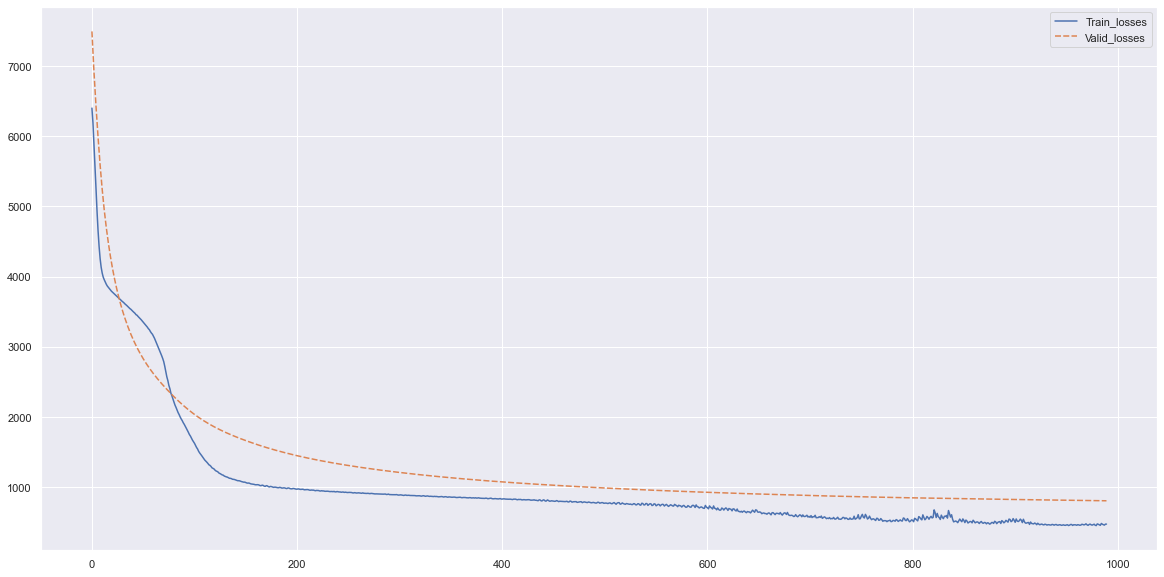

In [49]:
fig, ax = plt.subplots(figsize=(20, 10))
sns.set_theme(style="darkgrid")

sns.lineplot(data = pd.DataFrame({'Train_losses':losses_calendar[10:1000],'Valid_losses':val_losses_calendar[10:1000]}))
plt.show()

### evaluate

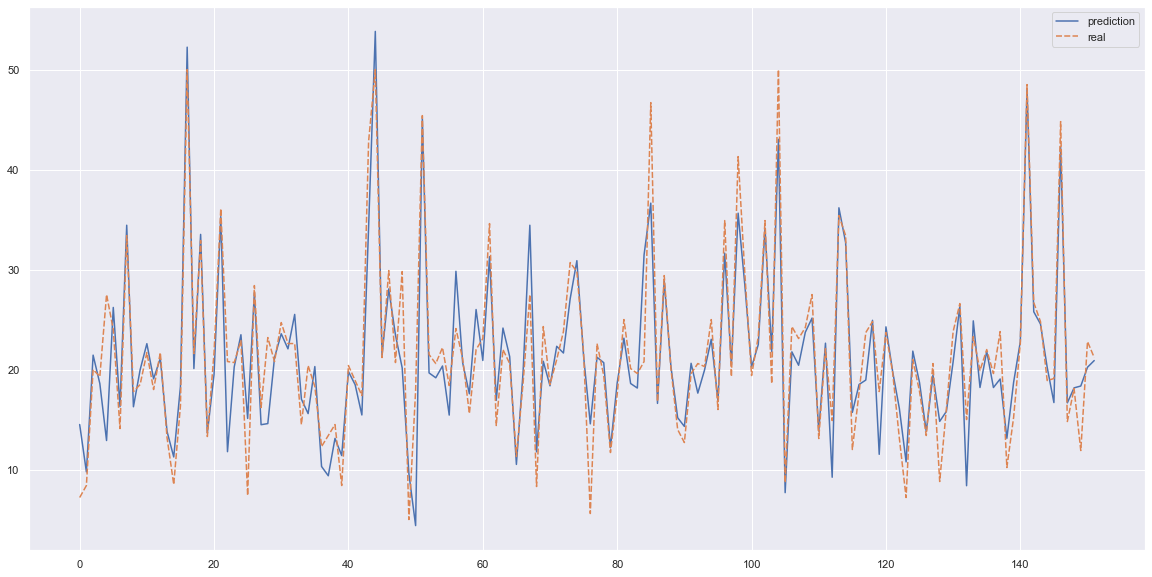

In [50]:
fig, ax = plt.subplots(figsize=(20, 10))
sns.set_theme(style="darkgrid")

sns.lineplot(data = pd.DataFrame({'prediction':pred_model_MLP,'real':y_test}))
plt.show()

Xboost

In [8]:
from xgboost import XGBRegressor

import data

In [9]:
data=sklearn.datasets.load_boston()['data']
target = sklearn.datasets.load_boston()['target']
X_train, X_test, y_train, y_test = train_test_split(data,target,test_size=0.3)


In [10]:
X_train.shape

(354, 13)

In [11]:
X_test.shape

(152, 13)

Train

In [12]:
model = XGBRegressor()
model = XGBRegressor(n_estimators=1000, max_depth=7, eta=0.1, subsample=0.7, colsample_bytree=0.8)
model.fit(X_train,y_train)

XGBRegressor(base_score=0.5, booster='gbtree', callbacks=None,
             colsample_bylevel=1, colsample_bynode=1, colsample_bytree=0.8,
             early_stopping_rounds=None, enable_categorical=False, eta=0.1,
             eval_metric=None, gamma=0, gpu_id=-1, grow_policy='depthwise',
             importance_type=None, interaction_constraints='',
             learning_rate=0.100000001, max_bin=256, max_cat_to_onehot=4,
             max_delta_step=0, max_depth=7, max_leaves=0, min_child_weight=1,
             missing=nan, monotone_constraints='()', n_estimators=1000,
             n_jobs=0, num_parallel_tree=1, predictor='auto', random_state=0,
             reg_alpha=0, ...)

Evaluate

In [13]:
pred_model = model.predict(X_test)

plot

In [14]:
mae=mean_absolute_error(pred_model,y_test)
mae

2.2777899861335755

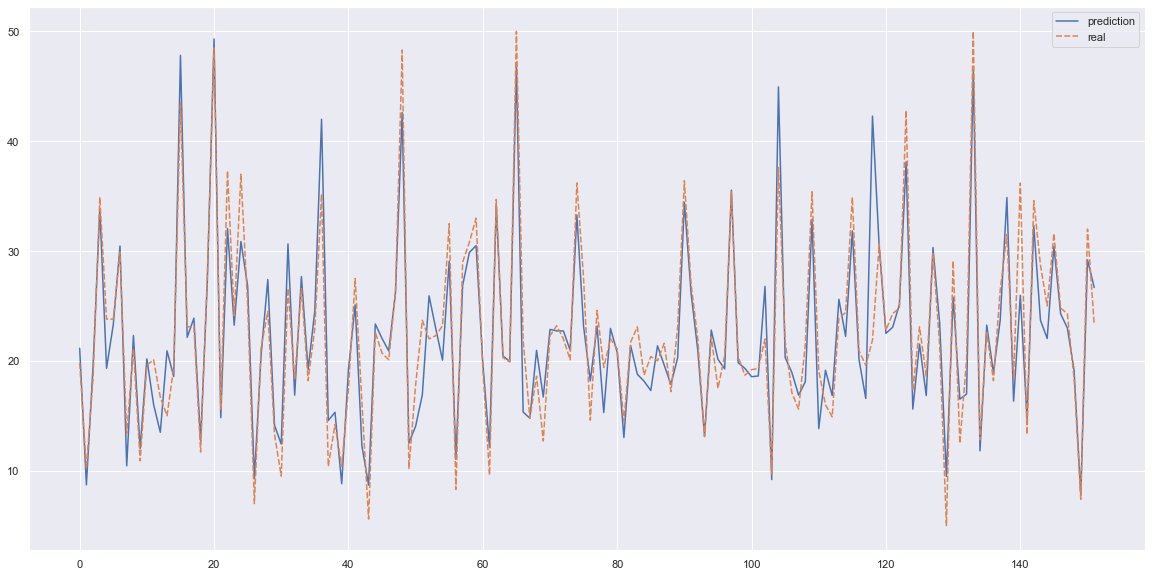

In [15]:
fig, ax = plt.subplots(figsize=(20, 10))
sns.set_theme(style="darkgrid")

sns.lineplot(data = pd.DataFrame({'prediction':pred_model,'real':y_test}))
plt.show()